# A client-held-out ranking benchmark for a March search-decline proxy

**Author:** Tahir123-dev  
**Study type:** Observational model evaluation · one monthly partition · grouped by client

## Abstract

This paper asks whether first-half-of-month search signals can rank client–content records that cross a later within-month impressions-decline proxy. Using one March 2026 slice of the v20260703 warehouse release, a class-balanced logistic model used five first-half features to rank eligible records, with second-half impressions supplying the proxy label. A 75/25 client-grouped split held out 10 clients (15,793 records) and kept them disjoint from 28 training clients. On that test set, the model measured Precision@50/100 of 0.44/0.41 versus 0.12/0.12 for a Week-4 CTR rule, with ROC-AUC of 0.615 versus 0.496. These are single-split observed ranking results for a threshold-derived March proxy, supporting only human-reviewed decision-support experiments—not causal refresh claims, calibrated risk estimates, or generalization across future months.

This notebook contains public-safe aggregate receipts and regenerates the figures embedded in the static paper. It does not download or expose warehouse records.

## 1. Question

**Research question:** Among client–content records with at least 100 first-half impressions in March 2026, do first-half search features rank records that meet a second-half impressions-decline proxy above a Week-4 CTR review rule when entire clients are held out?

**Decision supported:** whether a human-reviewed, small-scope triage experiment is worth evaluating—not whether a page should be refreshed, nor whether refreshing causes recovery.

The March 2026 FlyRank report provides context, not validation for this model. It describes mean word-count and page-age differences between growing and declining groups (p. 6), and reports a 7.88:1 growth-to-decline ratio in the 31–90-day freshness band (p. 9). For the first finding, could a prospective label help separate description from prediction, and could the differences be checked within brands? For the freshness result, could the underlying counts and uncertainty be shown by brand, and could a prospective comparison address which pages were selected for refresh? The 361+ day ratio depends on one declining page. These questions are about scope and validation, not the report's value; the observations are not causal evidence that refresh timing produces growth. See the linked Week-6 audit.

In [15]:
from pathlib import Path
import json
import shutil

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display

ROOT = Path.cwd().resolve()
while not (ROOT / "work" / "notebooks" / "w05_model.ipynb").is_file():
    if ROOT.parent == ROOT:
        raise FileNotFoundError("Could not locate the repository root from the notebook working directory.")
    ROOT = ROOT.parent

W05_NOTEBOOK = ROOT / "work" / "notebooks" / "w05_model.ipynb"
W07_METRICS = ROOT / "work" / "outputs" / "w07_playbook_metrics.json"
W07_ACTION_FIGURE = ROOT / "work" / "figures" / "w07_action_mix.png"
OUTPUTS = ROOT / "work" / "outputs"
FIGURES = ROOT / "work" / "figures"
SITE_ASSETS = ROOT / "work" / "site" / "assets"
for required in (W05_NOTEBOOK, W07_METRICS, W07_ACTION_FIGURE):
    if not required.is_file():
        raise FileNotFoundError(f"Required aggregate/source artifact is missing: {required.relative_to(ROOT)}")

with W07_METRICS.open(encoding="utf-8") as stream:
    w07 = json.load(stream)

model_metrics = {"Precision@50": 0.44, "Precision@100": 0.41, "ROC-AUC": 0.615, "Average precision": 0.226}
baseline_metrics = {"Precision@50": 0.12, "Precision@100": 0.12, "ROC-AUC": 0.496, "Average precision": 0.148}
test_base_rate = 0.147
assert w07["queue_rows"] == sum(w07["primary_archetype_counts_in_queue"].values()) == 500
assert w07["metrics"]["client_overlap"] == 0
print("Aggregate receipts loaded; no row-level data is read by this paper notebook.")

Aggregate receipts loaded; no row-level data is read by this paper notebook.


## 2. Data

The primary analysis uses the gated FlyRank warehouse release **v20260703**. Its `fact_content_daily_performance` table contains 78,835,655 daily report-date × client × content rows across 2025-01-27 through 2026-06-30. That is the release-table size, not the amount scanned for this study: the Week-5 analysis queried only the March 2026 partition.

The model table is one row per eligible client–content record aggregated over 2026-03-01–15. The outcome uses 2026-03-16–31. Records with fewer than 100 first-half impressions were excluded; this removes very low-volume, unstable ratios and defines the population to which the results apply. There were 77,540 eligible records from 38 represented clients. No content/client dimension table or fixed-window query table was joined. Public outputs contain aggregate metrics only, not client IDs, URLs, titles, queries, or individual records.

A separate Week-7 action-playbook prototype used the bundled anonymized starter snapshot (30,000 eligible rows; 32 clients), not the warehouse March experiment. Its aggregate action mix is shown separately and is not pooled with the Week-5 metrics.

In [16]:
data_scope = pd.DataFrame([
    {"item": "Warehouse release", "observed value": "v20260703"},
    {"item": "Source table", "observed value": "fact_content_daily_performance only"},
    {"item": "Full table size / date span", "observed value": "78,835,655 rows / 2025-01-27–2026-06-30"},
    {"item": "Queried partition", "observed value": "2026-03-01–2026-03-31 only"},
    {"item": "Eligible records / represented clients", "observed value": "77,540 / 38"},
    {"item": "Excluded", "observed value": "Records with <100 first-half impressions; no dimension or query-table joins"},
])
display(data_scope)
print("The 78.8M count describes the release table; this analysis used only the March partition.")

,item,observed value
0,Warehouse release,v20260703
1,Source table,fact_content_daily_performance only
2,Full table size / date span,"78,835,655 rows / 2025-01-27–2026-06-30"
3,Queried partition,2026-03-01–2026-03-31 only
4,Eligible records / represented clients,"77,540 / 38"
5,Excluded,Records with <100 first-half impressions; no d...


The 78.8M count describes the release table; this analysis used only the March partition.


## 3. Methodology

**Label.** An eligible record receives the observed decline-proxy label when second-half impressions are below 80% of first-half impressions. This is a threshold-derived within-month outcome, not a human editorial judgment or a measurement of recovery after a refresh.

**Features and leakage audit.** The logistic-regression ranker uses first-half impressions, clicks, average position, active search days, and impression standard deviation. All are measured before the outcome window. The second-half count is used only to construct the label. The ≥100-impression eligibility filter and first-half impressions are related to the label denominator by design, so results can reflect low-volume volatility or regression to the mean. The client grouping key is used for splitting only, never as a model feature.

**Model and baseline.** Median imputation with missing indicators, standard scaling, and class-balanced logistic regression (`max_iter=1000`, seed 42). The Week-4 rule flags first-half impressions ≥500, average position 1–20, and CTR <0.5%; its rule score ranks candidates. The rule was designed for CTR opportunities, not this decline proxy, so comparison is descriptive, not a contest of original purposes.

**Validation.** One 75/25 `GroupShuffleSplit` by client (`random_state=42`): 61,747 train records / 28 clients and 15,793 test records / 10 disjoint clients. The held-out proxy base rate was 0.147. No later-month, repeated-split, or prospective evaluation was run. Class-balanced scores order review priority; they are not calibrated probabilities.

In [17]:
feature_audit = pd.DataFrame([
    {"field": "First-half impressions, clicks, avg. position, active days, impression SD", "window/use": "2026-03-01–15; model inputs", "leakage assessment": "Available before outcome window; impressions also define eligibility and the label denominator."},
    {"field": "Second-half impressions", "window/use": "2026-03-16–31; label only", "leakage assessment": "Outcome-derived; excluded from model features."},
    {"field": "Client group", "window/use": "Validation split only", "leakage assessment": "Used to keep clients disjoint; excluded from estimator."},
    {"field": "Client/content dimensions and fixed-window query table", "window/use": "Not joined", "leakage assessment": "No additional future/context fields introduced."},
])
display(feature_audit)
split_receipt = pd.DataFrame([
    {"partition": "Train", "records": 61747, "clients": 28},
    {"partition": "Held-out test", "records": 15793, "clients": 10},
])
display(split_receipt)
assert split_receipt.loc[0, "clients"] + split_receipt.loc[1, "clients"] == 38

,field,window/use,leakage assessment
0,"First-half impressions, clicks, avg. position,...",2026-03-01–15; model inputs,Available before outcome window; impressions a...
1,Second-half impressions,2026-03-16–31; label only,Outcome-derived; excluded from model features.
2,Client group,Validation split only,Used to keep clients disjoint; excluded from e...
3,Client/content dimensions and fixed-window que...,Not joined,No additional future/context fields introduced.


,partition,records,clients
0,Train,61747,28
1,Held-out test,15793,10


## 4. Results (vs baseline)

The learned ranker measured a higher share of decline-proxy labels among its top 50 and top 100 held-out records than the Week-4 CTR heuristic. The chart reports both absolute counts and fractions, with the test-set base rate shown as a reference line. This is one observed client-held-out split; the result does not establish future-month stability. The heuristic's original purpose was to surface low-CTR opportunities, so its lower score against a different proxy is not evidence that its original use failed.

ROC-AUC was 0.615 for logistic regression and 0.496 for the rule; average precision was 0.226 and 0.148, respectively, against a 0.147 test base rate. At a fixed 0.5 cutoff, the model generated 4,206 false positives and 1,096 false negatives. These aggregate errors reinforce review-only use; no record-level examples are published.

In [18]:
ranking_results = pd.DataFrame([
    {"metric": "ROC-AUC", "Week-4 CTR rule": baseline_metrics["ROC-AUC"], "Logistic regression": model_metrics["ROC-AUC"]},
    {"metric": "Average precision", "Week-4 CTR rule": baseline_metrics["Average precision"], "Logistic regression": model_metrics["Average precision"]},
    {"metric": "Held-out base rate", "Week-4 CTR rule": test_base_rate, "Logistic regression": test_base_rate},
])
display(ranking_results.round(3))
print("Precision@K is shown in the chart generated in Section 7; the table reports the non-duplicated ranking metrics.")

,metric,Week-4 CTR rule,Logistic regression
0,ROC-AUC,0.496,0.615
1,Average precision,0.148,0.226
2,Held-out base rate,0.147,0.147


Precision@K is shown in the chart generated in Section 7; the table reports the non-duplicated ranking metrics.


## 5. Limitations

This is one monthly partition and one client-grouped split; it does not establish time-forward performance, stable performance across future clients, or calibrated risk estimates. The outcome is an impressions-ratio proxy, not a verified content-quality judgment, user outcome, or post-refresh recovery. Because first-half impressions are both a feature and part of eligibility/label construction, the ranking may partly reflect volume and short-window noise. There are no repeated holdouts or uncertainty intervals. The Week-4 CTR baseline targets a different task. Permutation importance is an association in this split, not a cause. The separate Week-7 starter-data prototype has overlapping rolling feature/label windows and is not independent validation. No production or ROI claim is supported.

In [19]:
unsupported_claims = pd.DataFrame([
    {"Not supported": "The model predicts content decay in general.", "Why": "One March rule-defined impressions proxy and one grouped split."},
    {"Not supported": "Refreshing a flagged page causes recovery.", "Why": "No intervention or post-refresh causal evaluation."},
    {"Not supported": "The score is a calibrated chance of decline.", "Why": "Class-balanced ranking scores were not calibrated."},
    {"Not supported": "The result generalizes to future months or every client.", "Why": "No time-forward or repeated external evaluation."},
    {"Not supported": "The baseline is ineffective.", "Why": "It was designed for CTR review, not this decline proxy."},
])
display(unsupported_claims)
print("No confidence intervals were available; all reported comparisons are descriptive observations from one split.")

,Not supported,Why
0,The model predicts content decay in general.,One March rule-defined impressions proxy and o...
1,Refreshing a flagged page causes recovery.,No intervention or post-refresh causal evaluat...
2,The score is a calibrated chance of decline.,Class-balanced ranking scores were not calibra...
3,The result generalizes to future months or eve...,No time-forward or repeated external evaluation.
4,The baseline is ineffective.,"It was designed for CTR review, not this decli..."


No confidence intervals were available; all reported comparisons are descriptive observations from one split.


## 6. Ranked recommendations

The action playbook ranks **human review tasks**, not page edits. Rank is practical triage priority, not expected causal lift. For a page with visible impressions but low CTR, check query intent and the search-result snippet before changing copy. For an observed decline, first check seasonality, technical changes, tracking, and demand; consider refresh only after a reviewer verifies a content gap. Treat freshness-band evidence as a prompt to inspect—not a universal refresh cadence. The 31–90-day ratio is observational, and the 361+ tail is sparse.

A reviewer should verify evidence, record the reason code, estimate analyst/content effort, and document an outcome before any action. Cost/value should be measured as review time plus any production cost versus the value of an independently verified, useful change; these data do not support ROI estimates. Do not automate publishing, deletion, redirects, legal/medical/brand-sensitive edits, or any irreversible action. Do not act on low-volume records or an uncalibrated score alone.

The Week-7 starter-data queue is a separate prototype: the aggregate top-500 action mix is 487 `visible_low_ctr`, 7 `observed_decline`, and 6 `general_review`. Its rolling windows may overlap the label period, so it is not future-period or causal evidence.

In [20]:
actions = pd.DataFrame([
    {"rank": 1, "reason code": "visible_low_ctr", "human-reviewed action": "Check query intent and title/snippet alignment.", "no-go": "Do not rewrite or publish automatically."},
    {"rank": 2, "reason code": "observed_decline", "human-reviewed action": "Check seasonality, demand, technical changes, and tracking before considering a refresh.", "no-go": "Do not equate the proxy label with recoverability."},
    {"rank": 3, "reason code": "general_review", "human-reviewed action": "Monitor or request context when evidence is incomplete.", "no-go": "Do not escalate solely from an uncalibrated score."},
])
display(actions)
print("Priority is for analyst triage only; no action is automated.")
print("Cost/value receipt: measure reviewer minutes and verified outcomes in a future pilot; no ROI is estimated here.")

,rank,reason code,human-reviewed action,no-go
0,1,visible_low_ctr,Check query intent and title/snippet alignment.,Do not rewrite or publish automatically.
1,2,observed_decline,"Check seasonality, demand, technical changes, ...",Do not equate the proxy label with recoverabil...
2,3,general_review,Monitor or request context when evidence is in...,Do not escalate solely from an uncalibrated sc...


Priority is for analyst triage only; no action is automated.
Cost/value receipt: measure reviewer minutes and verified outcomes in a future pilot; no ROI is estimated here.


## 7. Artifacts the paper embeds

The following cell writes only aggregate metrics and static figures. It copies the aggregate Week-7 action-mix figure into the site artifact directory. It does not export the ranked queue CSV or any row-level data.

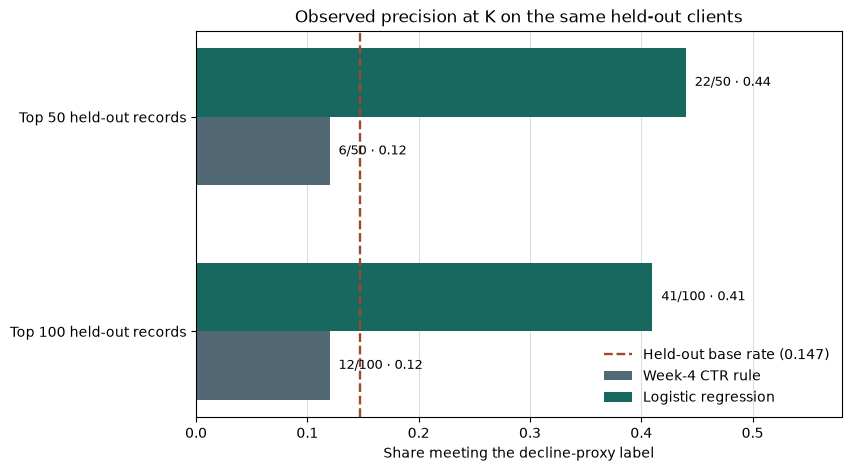

Wrote aggregate receipt: work\outputs\capstone_metrics.json
Wrote paper figures: work\figures\capstone_topk_precision.svg, work\figures\w07_action_mix.png


In [21]:
OUTPUTS.mkdir(parents=True, exist_ok=True)
FIGURES.mkdir(parents=True, exist_ok=True)
SITE_ASSETS.mkdir(parents=True, exist_ok=True)

fig, ax = plt.subplots(figsize=(8.4, 4.6), constrained_layout=True)
k_values = [50, 100]
rule_precision = [0.12, 0.12]
model_precision = [0.44, 0.41]
positions = np.arange(len(k_values))
bar_height = 0.32
ax.barh(positions + bar_height / 2, rule_precision, height=bar_height, color="#526874", label="Week-4 CTR rule")
ax.barh(positions - bar_height / 2, model_precision, height=bar_height, color="#17685f", label="Logistic regression")
ax.axvline(test_base_rate, color="#9b4a2d", linestyle="--", linewidth=1.7, label="Held-out base rate (0.147)")
for y, value, label in zip(positions + bar_height / 2, rule_precision, ["6/50 · 0.12", "12/100 · 0.12"]):
    ax.text(value + 0.008, y, label, va="center", fontsize=9)
for y, value, label in zip(positions - bar_height / 2, model_precision, ["22/50 · 0.44", "41/100 · 0.41"]):
    ax.text(value + 0.008, y, label, va="center", fontsize=9)
ax.set_yticks(positions, ["Top 50 held-out records", "Top 100 held-out records"])
ax.invert_yaxis()
ax.set_xlim(0, 0.58)
ax.set_xlabel("Share meeting the decline-proxy label")
ax.set_title("Observed precision at K on the same held-out clients")
ax.grid(axis="x", color="#d8e0df", linewidth=0.8)
ax.set_axisbelow(True)
ax.legend(frameon=False, loc="lower right")
fig.patch.set_facecolor("white")
ax.set_facecolor("white")
precision_figure = FIGURES / "capstone_topk_precision.svg"
fig.savefig(precision_figure, format="svg", bbox_inches="tight")
svg_text = precision_figure.read_text(encoding="utf-8")
precision_figure.write_text("\n".join(line.rstrip() for line in svg_text.splitlines()) + "\n", encoding="utf-8")
plt.show()
plt.close(fig)

shutil.copy2(precision_figure, SITE_ASSETS / precision_figure.name)
shutil.copy2(W07_ACTION_FIGURE, SITE_ASSETS / W07_ACTION_FIGURE.name)
receipt = {
    "scope": "One March 2026 warehouse partition; one client-grouped held-out split; aggregate-only.",
    "warehouse_release": "v20260703",
    "source_table": "fact_content_daily_performance",
    "release_table_rows": 78835655,
    "release_date_span": "2025-01-27 through 2026-06-30",
    "queried_partition": "2026-03-01 through 2026-03-31",
    "eligible_rows": 77540,
    "train": {"rows": 61747, "clients": 28},
    "test": {"rows": 15793, "clients": 10, "decline_proxy_base_rate": test_base_rate},
    "label": "Second-half impressions < 80% of first-half impressions; eligible first-half impressions >= 100.",
    "features": ["first-half impressions", "first-half clicks", "first-half average position", "active search days", "first-half impression standard deviation"],
    "metrics": {"logistic_regression": model_metrics, "week4_ctr_rule": baseline_metrics, "false_positives_at_0.5_cutoff": 4206, "false_negatives_at_0.5_cutoff": 1096},
    "week7_prototype": {"dataset": "separate bundled anonymized starter snapshot", "queue_rows": w07["queue_rows"], "action_mix": w07["primary_archetype_counts_in_queue"], "metric_scope": w07["metric_scope"]},
    "privacy": "No row-level records, client IDs, URLs, titles, or queries are included.",
}
metrics_path = OUTPUTS / "capstone_metrics.json"
metrics_path.write_text(json.dumps(receipt, indent=2) + "\n", encoding="utf-8")
assert (SITE_ASSETS / precision_figure.name).is_file()
assert (SITE_ASSETS / W07_ACTION_FIGURE.name).is_file()
print(f"Wrote aggregate receipt: {metrics_path.relative_to(ROOT)}")
print(f"Wrote paper figures: {precision_figure.relative_to(ROOT)}, {W07_ACTION_FIGURE.relative_to(ROOT)}")

## Self-check

Before you submit, confirm each line honestly:

- [x] Every section above is filled with narrative and aggregate code receipts.
- [x] Run this notebook top to bottom in the selected kernel and confirm the JSON/figures are regenerated.
- [x] No client names, URLs, private queries, queue rows, or warehouse row-level examples are exported.
- [x] Claims are scoped to observed, measured, directional, human-reviewed decision-support.
- [ ] Confirm the paper URL is live at the Pages address in `submission/paper_url.txt`.
- [ ] Commit the notebook, aggregate metrics, figures, paper page, and deployment workflow; submit the repository URL.